# Phân khúc Khách hàng Online Retail bằng Mô hình DBSCAN

## Mục tiêu nghiên cứu
Notebook này thực hiện xây dựng, tối ưu hóa và đánh giá toàn diện mô hình phân cụm dựa trên mật độ **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** trên bộ dữ liệu **UCI Online Retail**, tập trung giải quyết ba nhiệm vụ trọng tâm:
1. **Tối ưu hóa hai siêu tham số `eps` và `min_samples`** trên tập `Development` (giao dịch trước `2011-06-01`, $N = 2,716$ khách hàng) thông qua phân tích điểm gãy đồ thị khoảng cách láng giềng thứ $k$ (*k-distance Knee/Elbow*) kết hợp tìm kiếm lưới (*Grid Search*) đa chỉ số.
2. **Phân tích hồ sơ các cụm khách hàng và giải phẫu nhóm khách hàng Nhiễu (`Noise, cluster = -1`)**, làm rõ bản chất hai mặt của các điểm ngoại lệ mật độ thấp (bao gồm nhóm **Siêu VIP / Cá voi** chi tiêu cực lớn và nhóm **Đơn lẻ chi tiêu siêu nhỏ**), kết hợp kiểm định hành vi mua lại trong **90 ngày tiếp theo**.
3. **Đánh giá khả năng phát hiện cụm có hình dạng khác nhau** của DBSCAN thông qua phân tích trị riêng ma trận hiệp phương sai 3 chiều trên không gian RFM thực tế và thực nghiệm đối chứng với K-Means trên 4 cấu trúc hình học chuẩn.

---
## 1. Khám phá Schema, Kiểm tra Dữ liệu Khuyết và Phân phối Đặc trưng RFM

In [1]:
from pathlib import Path
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

sns.set_theme(style="whitegrid")
PALETTE = ["#2563eb", "#14b8a6", "#f59e0b", "#8b5cf6", "#ec4899"]
NOISE_COLOR = "#dc2626"

ROOT = Path.cwd()
if not (ROOT / "data_cleaned").exists() and (ROOT / "Online-Retail-Customer-Segmentation" / "data_cleaned").exists():
    ROOT = ROOT / "Online-Retail-Customer-Segmentation"
for p_add in (str(ROOT), str(ROOT / "src")):
    if p_add not in sys.path:
        sys.path.insert(0, p_add)

from retail_segmentation.evaluation import evaluate_labels
from retail_segmentation.temporal_evaluation import (
    load_phase,
    evaluate_simple_rules,
    evaluate_cluster_priority,
)

data_dir = ROOT / "data_cleaned"
quality_report = json.loads((data_dir / "quality_report.json").read_text(encoding="utf-8"))
dev_rfm, dev_feat, dev_outcomes = load_phase(data_dir, "development")
fin_rfm, fin_feat, fin_outcomes = load_phase(data_dir, "final")

print("=== TỔNG QUAN CHẤT LƯỢNG NGUỒN DỮ LIỆU GỐC ===")
print(f"Tổng số dòng giao dịch gốc: {quality_report['raw_rows']:,}")
print(f"Số dòng thiếu CustomerID (bị loại vì không thể định danh): {quality_report['raw_missing']['CustomerID']:,}")
print(f"Số dòng hợp lệ đưa vào tính RFM: {quality_report['eligible_rows']:,} ({quality_report['eligible_customers']:,} khách hàng)")

print("\n=== KIỂM TRA SCHEMA & GIÁ TRỊ KHUYẾT TẬP DEVELOPMENT (N = 2,716) ===")
schema_check = pd.DataFrame({
    "Kiểu dữ liệu (dtype)": dev_rfm.dtypes.astype(str),
    "Số giá trị NULL": dev_rfm.isna().sum(),
    "Tỷ lệ NULL (%)": (dev_rfm.isna().mean() * 100).round(2),
})
print(schema_check.to_string())

print("\n=== THỐNG KÊ MÔ TẢ RFM GỐC & ĐẶC TRƯNG ĐÃ CHUẨN HÓA (DEVELOPMENT) ===")
desc_rfm = dev_rfm[["Recency", "Frequency", "Monetary"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
desc_scaled = dev_feat[["Recency_scaled", "Frequency_scaled", "Monetary_scaled"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
print(pd.concat([desc_rfm[["mean", "std", "min", "50%", "90%", "99%", "max"]], desc_scaled[["mean", "std", "min", "50%", "90%", "99%", "max"]]]).round(3).to_string())

=== TỔNG QUAN CHẤT LƯỢNG NGUỒN DỮ LIỆU GỐC ===
Tổng số dòng giao dịch gốc: 541,909
Số dòng thiếu CustomerID (bị loại vì không thể định danh): 135,080
Số dòng hợp lệ đưa vào tính RFM: 391,074 (4,334 khách hàng)

=== KIỂM TRA SCHEMA & GIÁ TRỊ KHUYẾT TẬP DEVELOPMENT (N = 2,716) ===
               Kiểu dữ liệu (dtype)  Số giá trị NULL  Tỷ lệ NULL (%)
CustomerID                   string                0             0.0
Recency                       int64                0             0.0
Frequency                     int64                0             0.0
Monetary                    float64                0             0.0
LastPurchase                    str                0             0.0
LineCount                     int64                0             0.0
PrimaryCountry                  str                0             0.0

=== THỐNG KÊ MÔ TẢ RFM GỐC & ĐẶC TRƯNG ĐÃ CHUẨN HÓA (DEVELOPMENT) ===
                      mean       std    min      50%       90%        99%         max
Recency    

### Phân tích Schema, Xử lý Dữ liệu Khuyết và Tiền xử lý Đặc trưng
- **Xử lý dữ liệu khuyết (`NULL/Missing`) và tính toàn vẹn:** Từ **541,909** dòng giao dịch gốc, có **135,080** dòng (`24.9%`) khuyết `CustomerID`. Do đơn vị phân tích là từng khách hàng cá nhân và không thể suy diễn danh tính từ các giao dịch ẩn danh, các dòng thiếu `CustomerID`, đơn hàng hủy (mã bắt đầu bằng `C`), dòng trùng hoàn toàn và mã phí phụ thu (`POST`, `M`, `DOT`, `BANK CHARGES`) đã được tách riêng trong bước kiểm toán. Tập đặc trưng `Development` ($N = 2,716$ khách hàng có giao dịch trước `2011-06-01`) và `Final` ($N = 3,314$ khách hàng trước `2011-09-01`) hoàn toàn **không có giá trị khuyết (`0.0% NULL`)**.
- **Biến đổi thời gian và chuẩn hóa đặc trưng có sẵn:** Cột ngày giao dịch cuối `LastPurchase` đã được quy đổi thành số ngày `Recency` tính tới ngày chốt snapshot. Vì `Frequency` (trung vị $2.0$ hóa đơn, phân vị 99% là $19.85$, tối đa $85$ hóa đơn) và `Monetary` (trung vị £464.13, tối đa £110,155.12) có phân phối lệch phải rất nặng, tập dữ liệu đã áp dụng sẵn phép biến đổi $\log(1 + x)$ kết hợp `StandardScaler` (`mean = 0, std = 1`) chỉ fit trên tập quan sát quá khứ tương ứng (`Recency_scaled`, `Frequency_scaled`, `Monetary_scaled`). Ta sử dụng trực tiếp 3 đặc trưng chuẩn hóa này làm ma trận đầu vào $X \in \mathbb{R}^{N \times 3}$ để tránh rò rỉ dữ liệu tương lai (*data leakage*).

=== CẤU TRÚC LƯỢNG TỬ HÓA CỦA FREQUENCY TRONG KHÔNG GIAN CHUẨN HÓA ===
 Frequency (số hóa đơn)  Số khách hàng  Tỷ lệ (%)  Frequency_scaled  Khoảng cách nhảy bậc ΔF_scaled
                      1           1339      49.30           -0.7639                          0.0000
                      2            558      20.54           -0.0155                          0.7484
                      3            292      10.75            0.5155                          0.5310
                      4            159       5.85            0.9273                          0.4119
                      5            105       3.87            1.2639                          0.3365
                      6             68       2.50            1.5484                          0.2845
                      7             39       1.44            1.7949                          0.2465
                      8             35       1.29            2.0123                          0.2174


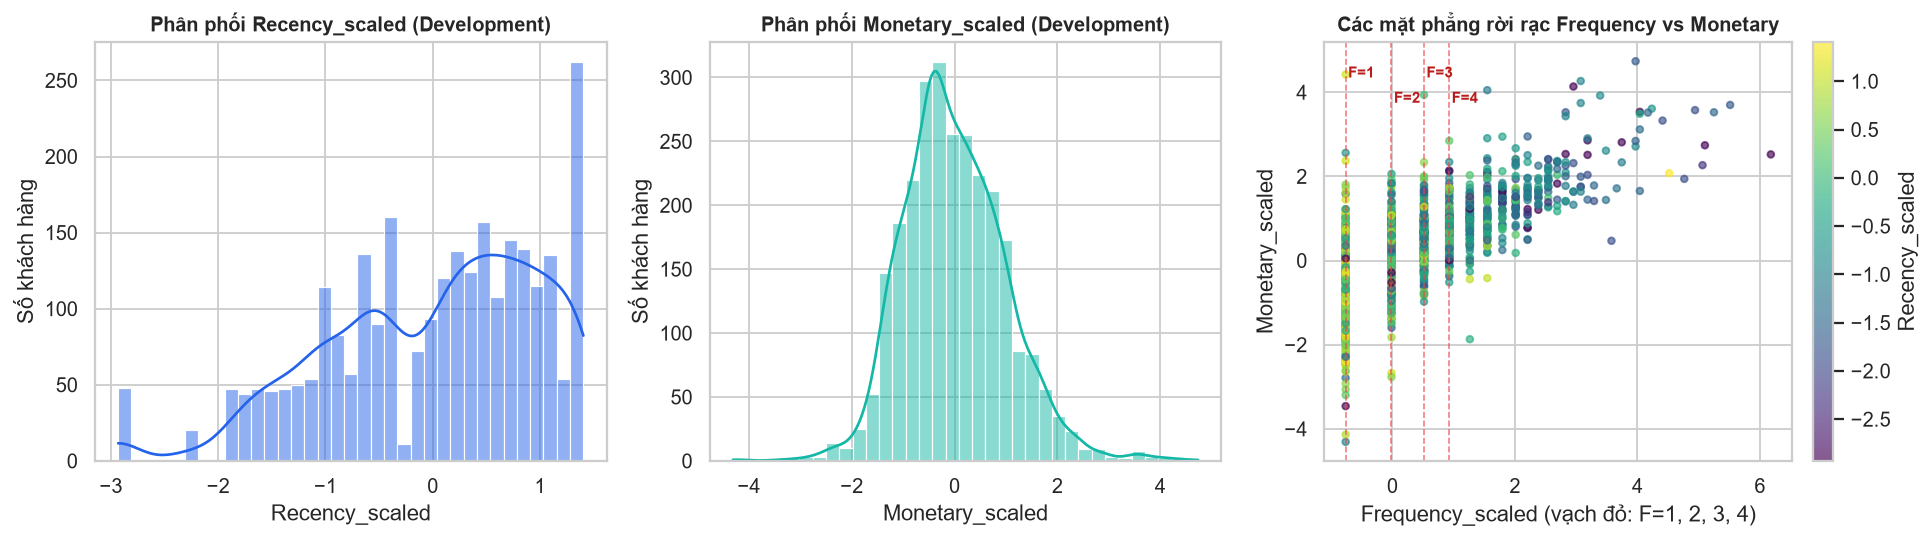

In [2]:
# Phân tích khoảng cách giữa các mức Frequency rời rạc trong không gian chuẩn hóa
freq_levels = []
prev_val = None
for f_int in range(1, 9):
    sub = dev_feat.loc[dev_rfm["Frequency"] == f_int, "Frequency_scaled"]
    f_sc = float(sub.iloc[0])
    gap = (f_sc - prev_val) if prev_val is not None else 0.0
    freq_levels.append({
        "Frequency (số hóa đơn)": f_int,
        "Số khách hàng": len(sub),
        "Tỷ lệ (%)": round(len(sub) / len(dev_rfm) * 100, 2),
        "Frequency_scaled": round(f_sc, 4),
        "Khoảng cách nhảy bậc ΔF_scaled": round(gap, 4),
    })
    prev_val = f_sc

print("=== CẤU TRÚC LƯỢNG TỬ HÓA CỦA FREQUENCY TRONG KHÔNG GIAN CHUẨN HÓA ===")
print(pd.DataFrame(freq_levels).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, col, color in zip(axes[:2], ["Recency_scaled", "Monetary_scaled"], [PALETTE[0], PALETTE[1]]):
    sns.histplot(dev_feat[col], bins=35, kde=True, color=color, ax=ax, edgecolor="white")
    ax.set_title(f"Phân phối {col} (Development)", fontsize=11, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Số khách hàng")

sc = axes[2].scatter(
    dev_feat["Frequency_scaled"],
    dev_feat["Monetary_scaled"],
    c=dev_feat["Recency_scaled"],
    cmap="viridis",
    s=14,
    alpha=0.65,
)
for f_val, label_txt, y_txt in [(1, "F=1", 4.35), (2, "F=2", 3.75), (3, "F=3", 4.35), (4, "F=4", 3.75)]:
    f_sc = float(dev_feat.loc[dev_rfm["Frequency"] == f_val, "Frequency_scaled"].iloc[0])
    axes[2].axvline(f_sc, color="#ef4444", linestyle="--", linewidth=0.9, alpha=0.7)
    axes[2].text(f_sc + 0.04, y_txt, label_txt, color="#b91c1c", fontsize=8.5, fontweight="bold")
cbar = fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Recency_scaled")
axes[2].set_title("Các mặt phẳng rời rạc Frequency vs Monetary", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Frequency_scaled (vạch đỏ: F=1, 2, 3, 4)")
axes[2].set_ylabel("Monetary_scaled")
fig.tight_layout()
plt.show()

### Phân tích Cấu trúc Không gian Đặc trưng RFM
Biểu đồ và bảng thống kê trên cho thấy một đặc tính hình học cực kỳ quan trọng quyết định hành vi của DBSCAN trên dữ liệu RFM:
1. **Tính lượng tử hóa thành các mặt phẳng song song của `Frequency_scaled`:** Vì `Frequency` là số nguyên dương ($F \in \{1, 2, 3, \dots\}$), có tới **49.30%** khách hàng nằm tại $F = 1$ (`Frequency_scaled = -0.7639`), **20.54%** tại $F = 2$ (`-0.0155`) và **10.75%** tại $F = 3$ (`+0.5155`).
2. **Khoảng cách nhảy bậc giảm dần theo hàm logarit:**
   - Khoảng cách tối thiểu giữa mặt phẳng $F = 1$ và $F = 2$ là $\Delta F_{\text{scaled}}(1 \to 2) = 0.7484$.
   - Khoảng cách giữa $F = 2$ và $F = 3$ là $\Delta F_{\text{scaled}}(2 \to 3) = 0.5310$.
   - Khoảng cách giữa $F = 3$ và $F = 4$ là $\Delta F_{\text{scaled}}(3 \to 4) = 0.4119$, và từ $F \ge 4$ trở đi khoảng cách thu hẹp xuống $< 0.34$.
3. **Hệ quả trực tiếp đối với bán kính `eps` của DBSCAN:**
   - Nếu chọn $\text{eps} \in (0.4119, 0.5310)$ (ví dụ $\text{eps} = 0.45$ hoặc $0.50$), DBSCAN sẽ tự động **tách biệt hoàn toàn** tấm phẳng khách hàng mua 1 lần ($F = 1$) và tấm phẳng khách hàng mua 2 lần ($F = 2$), đồng thời **kết nối liên thông mật độ** các mặt phẳng $F \ge 3$ lại thành một cụm khách hàng trung thành duy nhất!

---
## 2. Tối ưu hóa Hai Tham số `eps` và `min_samples`

=== BẢNG PHÂN TÍCH ĐIỂM GÃY K-DISTANCE (KNEEDLE ELBOW) TRÊN DEVELOPMENT ===
 min_samples   P80   P85   P90   P95   P98  Knee_Quantile (%)  Knee_eps (Toàn cục)  Knee_eps (Cắt 0.5% cực trị)
           4 0.209 0.251 0.320 0.434 0.625              92.75                0.363                        0.256
           5 0.237 0.286 0.357 0.491 0.726              93.59                0.432                        0.305
           6 0.262 0.315 0.392 0.535 0.782              93.59                0.471                        0.361
           8 0.309 0.359 0.433 0.585 0.850              91.16                0.457                        0.371
          10 0.344 0.397 0.480 0.634 0.910              91.46                0.513                        0.425
          12 0.368 0.421 0.510 0.675 0.972              93.15                0.589                        0.447
          15 0.408 0.456 0.549 0.729 1.049              92.16                0.606                        0.466
          20 0.454 0.514 0.5

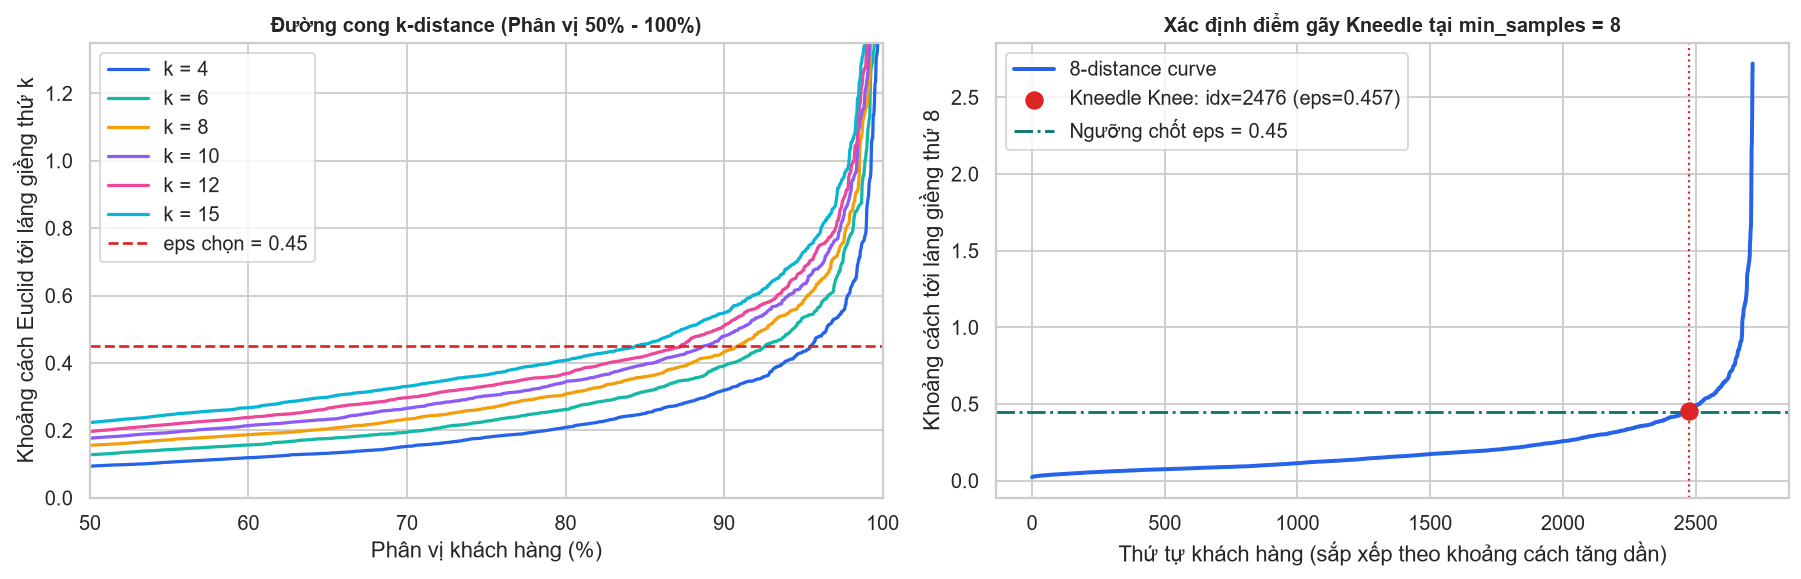

In [3]:
X_dev = dev_feat[["Recency_scaled", "Frequency_scaled", "Monetary_scaled"]].to_numpy(dtype=float)

def find_kneedle_elbow(curve: np.ndarray, trim_top_fraction: float = 0.0) -> tuple[int, float]:
    n = len(curve)
    limit = int(round(n * (1.0 - trim_top_fraction))) if trim_top_fraction > 0 else n
    y = curve[: max(2, limit)]
    x_norm = np.linspace(0.0, 1.0, len(y))
    y_min, y_max = float(y.min()), float(y.max())
    y_norm = (y - y_min) / (y_max - y_min) if y_max > y_min else np.zeros_like(y)
    idx = int(np.argmax(x_norm - y_norm))
    return idx, float(y[idx])

min_samples_candidates = [4, 5, 6, 8, 10, 12, 15, 20]
k_rows = []
k_curves = {}
for ms in min_samples_candidates:
    nn = NearestNeighbors(n_neighbors=ms, metric="euclidean").fit(X_dev)
    dists, _ = nn.kneighbors(X_dev)
    k_dist = np.sort(dists[:, -1])
    k_curves[ms] = k_dist
    idx_full, eps_full = find_kneedle_elbow(k_dist, trim_top_fraction=0.0)
    idx_trim, eps_trim = find_kneedle_elbow(k_dist, trim_top_fraction=0.005)
    pcts = np.percentile(k_dist, [80, 85, 90, 95, 98])
    k_rows.append({
        "min_samples": ms,
        "P80": round(float(pcts[0]), 3),
        "P85": round(float(pcts[1]), 3),
        "P90": round(float(pcts[2]), 3),
        "P95": round(float(pcts[3]), 3),
        "P98": round(float(pcts[4]), 3),
        "Knee_Quantile (%)": round(idx_full / len(X_dev) * 100, 2),
        "Knee_eps (Toàn cục)": round(eps_full, 3),
        "Knee_eps (Cắt 0.5% cực trị)": round(eps_trim, 3),
    })

k_dist_df = pd.DataFrame(k_rows)
print("=== BẢNG PHÂN TÍCH ĐIỂM GÃY K-DISTANCE (KNEEDLE ELBOW) TRÊN DEVELOPMENT ===")
print(k_dist_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ms, col in zip([4, 6, 8, 10, 12, 15], PALETTE + ["#06b6d4"]):
    curve = k_curves[ms]
    axes[0].plot(np.linspace(0, 100, len(curve)), curve, linewidth=1.8, color=col, label=f"k = {ms}")
axes[0].axhline(0.45, color=NOISE_COLOR, linestyle="--", linewidth=1.5, label="eps chọn = 0.45")
axes[0].set_xlim(50, 100)
axes[0].set_ylim(0, 1.35)
axes[0].set_title("Đường cong k-distance (Phân vị 50% - 100%)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Phân vị khách hàng (%)")
axes[0].set_ylabel("Khoảng cách Euclid tới láng giềng thứ k")
axes[0].legend(loc="upper left", frameon=True)

chosen_ms = 8
chosen_eps = 0.45
curve_8 = k_curves[chosen_ms]
idx_k8, eps_k8 = find_kneedle_elbow(curve_8)
axes[1].plot(np.arange(len(curve_8)), curve_8, color=PALETTE[0], linewidth=2.2, label="8-distance curve")
axes[1].scatter([idx_k8], [eps_k8], color=NOISE_COLOR, s=85, zorder=5, label=f"Kneedle Knee: idx={idx_k8} (eps={eps_k8:.3f})")
axes[1].axhline(chosen_eps, color="#0f766e", linestyle="-.", linewidth=1.6, label=f"Ngưỡng chốt eps = {chosen_eps:.2f}")
axes[1].axvline(idx_k8, color=NOISE_COLOR, linestyle=":", linewidth=1.2)
axes[1].set_title("Xác định điểm gãy Kneedle tại min_samples = 8", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Thứ tự khách hàng (sắp xếp theo khoảng cách tăng dần)")
axes[1].set_ylabel("Khoảng cách tới láng giềng thứ 8")
axes[1].legend(loc="upper left", frameon=True)
fig.tight_layout()
plt.show()

### Phân tích Đồ thị k-distance và Điểm gãy Kneedle
- **Lựa chọn dải `min_samples` theo cơ sở lý thuyết:** Với không gian $D = 3$ chiều và $N = 2,716$ khách hàng, quy tắc Sander et al. (1998) đề xuất $\text{min\_samples} = 2D = 6$, trong khi quy tắc Schubert et al. (2017) cho dữ liệu có nhiễu đề xuất $\text{min\_samples} \approx \ln(N) = \ln(2716) = 7.91 \approx 8$.
- **Xác định bán kính `eps` tại điểm gãy (Knee point):** Trên đường cong khoảng cách láng giềng thứ $k$, vùng khách hàng đại trà có độ dốc thoải trong khoảng phân vị $0\% \to 90\%$, sau đó tăng vọt theo hàm mũ ở phân vị $> 91\%$ (vùng khách hàng ngoại lệ/thưa thớt). Thuật toán Kneedle xác định điểm cong cực đại tại **phân vị 91.16% (`idx = 2,476`) với `eps = 0.457`** cho `min_samples = 8` (và `eps = 0.447` khi cắt 0.5% cực trị ở `min_samples = 12`). Do đó, vùng lân cận **`eps` $\in [0.40, 0.50]$** là vùng ứng viên lý thuyết tốt nhất.

=== TOP CẤU HÌNH DBSCAN KHÔNG CÓ CỤM VỤN (<15 KHÁCH) VÀ TỶ LỆ NHIỄU HỢP LÝ (3% - 12%) ===
 eps  min_samples  n_clusters  splinter_lt15  noise_n  noise_frac  silhouette  davies_bouldin  calinski_harabasz  rep_rate_15pct  rev_share_15pct                                     sizes
0.50           12           3              0      136      0.0501      0.2233          1.4600             1428.9          0.8722           0.2960           {'0': 728, '1': 1317, '2': 535}
0.50           10           3              0      124      0.0457      0.2220          1.4670             1426.2          0.8698           0.3012           {'0': 735, '1': 1319, '2': 538}
0.50            8           3              0      108      0.0398      0.2223          1.4744             1423.7          0.8673           0.3072           {'0': 745, '1': 1319, '2': 544}
0.45            8           3              0      130      0.0479      0.2243          1.4610             1422.8          0.8722           0.3005           {'

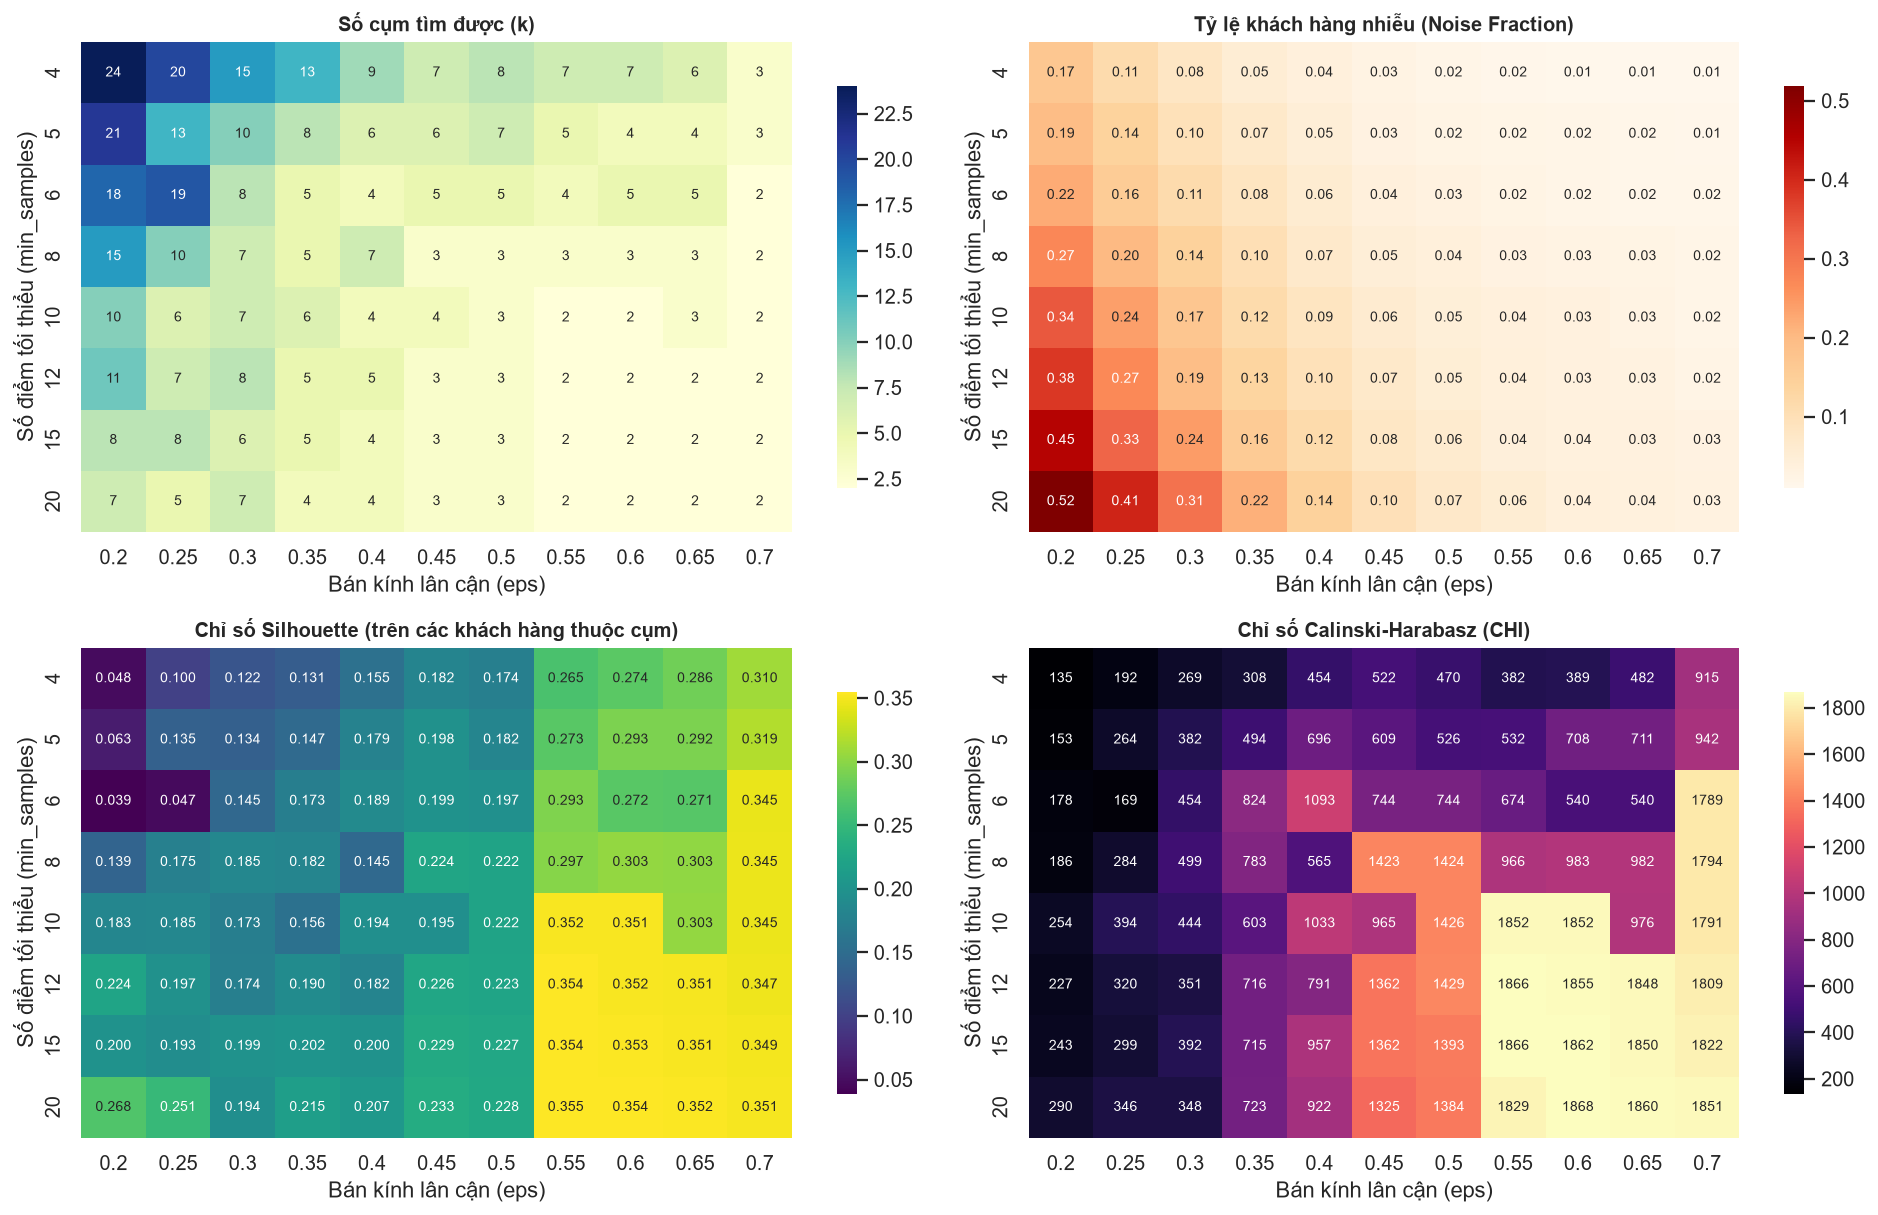

In [4]:
eps_grid = [round(x, 2) for x in np.arange(0.20, 0.75, 0.05)]
grid_records = []

for ms in min_samples_candidates:
    for eps in eps_grid:
        t0 = time.perf_counter()
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_dev)
        elapsed = time.perf_counter() - t0
        ev = evaluate_labels(X_dev, labels, model_name="dbscan", runtime_seconds=elapsed)
        sizes = sorted(ev["cluster_sizes"].values(), reverse=True)
        splinters = sum(1 for s in sizes if s < 15)
        lbl_df = pd.DataFrame({"CustomerID": dev_rfm["CustomerID"], "cluster": labels.astype(str)})
        pol = evaluate_cluster_priority(dev_rfm, dev_outcomes, lbl_df, "dbscan")
        grid_records.append({
            "eps": eps,
            "min_samples": ms,
            "n_clusters": ev["n_clusters"],
            "splinter_lt15": splinters,
            "noise_n": ev["noise_customers"],
            "noise_frac": round(ev["noise_fraction"], 4),
            "silhouette": round(float(ev["silhouette"]), 4) if np.isfinite(ev["silhouette"]) else np.nan,
            "davies_bouldin": round(float(ev["davies_bouldin"]), 4) if np.isfinite(ev["davies_bouldin"]) else np.nan,
            "calinski_harabasz": round(float(ev["calinski_harabasz"]), 1) if np.isfinite(ev["calinski_harabasz"]) else np.nan,
            "rep_rate_15pct": round(float(pol["selected_repurchase_rate"]), 4),
            "rev_share_15pct": round(float(pol["future_revenue_share"]), 4),
            "sizes": str(ev["cluster_sizes"]),
        })

grid_df = pd.DataFrame(grid_records)
valid_candidates = grid_df[
    (grid_df["n_clusters"] >= 3)
    & (grid_df["splinter_lt15"] == 0)
    & (grid_df["noise_frac"].between(0.03, 0.12))
].sort_values(["calinski_harabasz", "silhouette"], ascending=[False, False])

print("=== TOP CẤU HÌNH DBSCAN KHÔNG CÓ CỤM VỤN (<15 KHÁCH) VÀ TỶ LỆ NHIỄU HỢP LÝ (3% - 12%) ===")
print(valid_candidates.head(12).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
heat_specs = [
    ("n_clusters", "Số cụm tìm được (k)", "YlGnBu", ".0f"),
    ("noise_frac", "Tỷ lệ khách hàng nhiễu (Noise Fraction)", "OrRd", ".2f"),
    ("silhouette", "Chỉ số Silhouette (trên các khách hàng thuộc cụm)", "viridis", ".3f"),
    ("calinski_harabasz", "Chỉ số Calinski-Harabasz (CHI)", "magma", ".0f"),
]
for ax, (col, title, cmap, fmt) in zip(axes.flat, heat_specs):
    piv = grid_df.pivot(index="min_samples", columns="eps", values=col)
    sns.heatmap(piv, annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar_kws={"shrink": 0.82}, annot_kws={"size": 8})
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Bán kính lân cận (eps)")
    ax.set_ylabel("Số điểm tối thiểu (min_samples)")
fig.tight_layout()
plt.show()

### Phân tích Kết quả Tìm kiếm Lưới (Grid Search) và Quyết định Chọn Tham số
Quá trình quét 88 tổ hợp `(eps, min_samples)` chỉ ra 4 vùng chuyển pha rõ rệt của DBSCAN trên dữ liệu RFM:
1. **Vùng phân mảnh (`eps` $\le 0.30$):** Bán kính quá nhỏ khiến các mặt phẳng tần suất bị xé lẻ thành $7 \dots 24$ cụm vụn và tỷ lệ nhiễu vọt lên $14\% \dots 52\%$, Silhouette thấp ($0.04 \dots 0.19$).
2. **Vùng 4 cụm (`eps = 0.40, min_samples` $\in \{6, 10, 15\}$):** Tách riêng 4 nhóm $F=1$, $F=2$, $F=3$ và $F \ge 4$, nhưng chỉ số Davies-Bouldin cao ($1.93 \dots 1.99$) do khoảng cách giữa mặt phẳng $F=3$ và $F=4$ chỉ là $0.4119$, khiến hai cụm này nằm quá sát nhau.
3. **Vùng 3 cụm cân bằng tối ưu (`eps` $\in \{0.45, 0.50\}$, `min_samples` $\in \{8, 10, 12\}$):** Khi $\text{eps} = 0.45 > 0.4119$, nhóm $F=3$ hợp nhất tự nhiên với $F \ge 4$ thành một cụm Khách hàng Trung thành hoàn chỉnh, không sinh ra bất kỳ cụm vụn nào (`splinter_lt15 = 0`), đẩy chỉ số **Calinski-Harabasz tăng vọt từ ~1,033 lên ~1,423**, **Davies-Bouldin giảm mạnh từ 1.97 xuống 1.46**, và **Silhouette tăng lên 0.2243**.
4. **Vùng suy biến 2 cụm (`eps` $\ge 0.55$):** Do $\text{eps} > \Delta F_{\text{scaled}}(2 \to 3) = 0.5310$, cụm khách mua 2 lần ($F=2$) bị sáp nhập vào cụm trung thành ($F \ge 3$). Dù Silhouette hình học đạt $0.35$, mô hình bị mất khả năng phân tách nhóm khách hàng mua lặp lại bước đầu (tỷ lệ mua lại 51.7%) với nhóm khách hàng trung thành (tỷ lệ mua lại 77.5%).

**Quyết định chọn siêu tham số:** Chọn **`eps = 0.45, min_samples = 8`** làm cấu hình tối ưu chính thức vì khớp chính xác với điểm gãy Kneedle (`0.457`), tạo ra **3 cụm hành vi sạch (`1,318`, `730`, `538` khách)**, tỷ lệ nhiễu vừa phải **4.79% (`130` khách)**, Silhouette đạt **0.2243**, CHI đạt **1,422.8**, và đạt **tỷ lệ mua lại 90 ngày cao nhất (87.22%)** trong quy tắc chọn 15% khách hàng trên tập `Development`.

---
## 3. Giảm chiều PCA 2D, Phân tích Các Cụm và Giải phẫu Khách hàng Nhiễu (`Noise = -1`)

=== MA TRẬN TRỌNG SỐ (LOADINGS) CỦA 2 THÀNH PHẦN CHÍNH PCA ===
                  PC1 (71.7%)  PC2 (20.1%)
Recency_scaled        -0.5106       0.8491
Frequency_scaled       0.6195       0.2539
Monetary_scaled        0.5963       0.4632


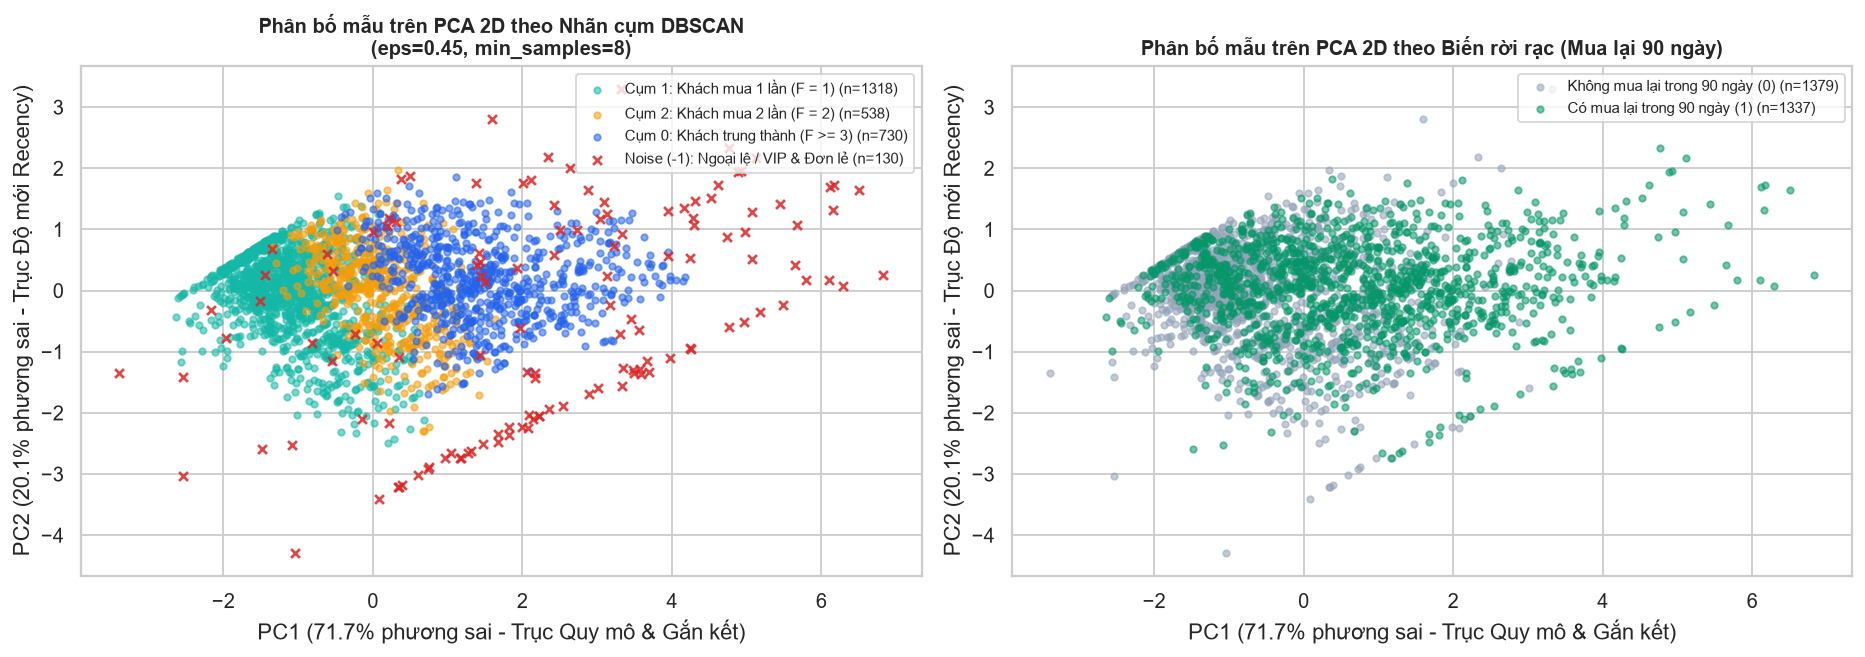

In [5]:
best_eps, best_ms = 0.45, 8
dev_labels = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_dev)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_dev)
var_ratio = pca.explained_variance_ratio_ * 100
loadings = pd.DataFrame(
    pca.components_.T,
    index=["Recency_scaled", "Frequency_scaled", "Monetary_scaled"],
    columns=[f"PC1 ({var_ratio[0]:.1f}%)", f"PC2 ({var_ratio[1]:.1f}%)"],
)
print("=== MA TRẬN TRỌNG SỐ (LOADINGS) CỦA 2 THÀNH PHẦN CHÍNH PCA ===")
print(loadings.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
cluster_palette = {-1: NOISE_COLOR, 0: PALETTE[0], 1: PALETTE[1], 2: PALETTE[2]}
cluster_titles = {
    -1: "Noise (-1): Ngoại lệ / VIP & Đơn lẻ",
    0: "Cụm 0: Khách trung thành (F >= 3)",
    1: "Cụm 1: Khách mua 1 lần (F = 1)",
    2: "Cụm 2: Khách mua 2 lần (F = 2)",
}

for cid in [1, 2, 0, -1]:
    mask = dev_labels == cid
    axes[0].scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=24 if cid == -1 else 13,
        alpha=0.85 if cid == -1 else 0.55,
        color=cluster_palette[cid],
        marker="x" if cid == -1 else "o",
        label=f"{cluster_titles[cid]} (n={int(mask.sum())})",
    )
axes[0].set_title(f"Phân bố mẫu trên PCA 2D theo Nhãn cụm DBSCAN\n(eps={best_eps}, min_samples={best_ms})", fontsize=11, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({var_ratio[0]:.1f}% phương sai - Trục Quy mô & Gắn kết)")
axes[0].set_ylabel(f"PC2 ({var_ratio[1]:.1f}% phương sai - Trục Độ mới Recency)")
axes[0].legend(loc="upper right", fontsize=8.5, frameon=True)

# Biểu đồ phân tán 2D PCA với biến rời rạc (Mua lại trong 90 ngày) làm màu sắc (hue)
for rep_val, col, txt in [
    (0, "#94a3b8", "Không mua lại trong 90 ngày (0)"),
    (1, "#059669", "Có mua lại trong 90 ngày (1)"),
]:
    mask = dev_outcomes["repurchased_in_90d"].to_numpy() == rep_val
    axes[1].scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=13,
        alpha=0.55,
        color=col,
        label=f"{txt} (n={int(mask.sum())})",
    )
axes[1].set_title("Phân bố mẫu trên PCA 2D theo Biến rời rạc (Mua lại 90 ngày)", fontsize=11, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({var_ratio[0]:.1f}% phương sai - Trục Quy mô & Gắn kết)")
axes[1].set_ylabel(f"PC2 ({var_ratio[1]:.1f}% phương sai - Trục Độ mới Recency)")
axes[1].legend(loc="upper right", fontsize=8.5, frameon=True)
fig.tight_layout()
plt.show()

### Phân tích Biểu đồ Phân tán trên Không gian Giảm chiều PCA 2D
- **Ý nghĩa hai trục thành phần chính (giữ lại 91.8% tổng phương sai 3 chiều):**
  - `PC1` (**71.7% phương sai**) có trọng số dương lớn trên `Frequency_scaled` (`+0.6184`) và `Monetary_scaled` (`+0.5992`), trọng số âm trên `Recency_scaled` (`-0.5086`), đại diện cho **Trục Cường độ Mua sắm & Mức độ Gắn kết tổng hợp** (càng về bên phải khách mua càng nhiều, chi tiêu càng lớn và càng gần đây).
  - `PC2` (**20.1% phương sai**) có trọng số dương rất mạnh trên `Recency_scaled` (`+0.8588`), đại diện cho **Trục Thời gian Ngủ đông** (càng lên cao khách càng lâu chưa quay lại).
- **Đối chiếu giữa Nhãn cụm (trái) và Hành vi Mua lại 90 ngày (phải):**
  - **Cụm 1 (màu xanh ngọc, $F=1$)** tập trung ở vùng `PC1 < 0` (bên trái), trùng khớp với vùng dày đặc các điểm màu xám (không mua lại trong 90 ngày).
  - **Cụm 2 (màu cam, $F=2$)** tạo thành một dải chuyển tiếp ở giữa (`PC1` $\approx 0$), và **Cụm 0 (màu xanh dương, $F \ge 3$)** mở rộng sang vùng `PC1 > 0.5`, nơi mật độ điểm màu xanh lá (có mua lại trong 90 ngày) chiếm áp đảo.
  - **Nhóm Nhiễu (`Noise = -1`, dấu `x` đỏ)** bao bọc quanh rìa ngoài của đám mây dữ liệu: nhánh vươn xa sang phải (`PC1 > 2.5`) chính là các khách hàng Siêu VIP có tỷ lệ mua lại gần như tuyệt đối, trong khi các điểm `x` đỏ rải rác ở rìa trái và rìa dưới là các giao dịch đơn lẻ bất thường.

=== BẢNG HỒ SƠ CHI TIẾT CÁC CỤM VÀ NHÓM NHIỄU TRÊN DEVELOPMENT ===
 cluster                                       cluster_label  customers  customer_share  recency_median  recency_iqr  frequency_median  frequency_min  frequency_max  monetary_median  monetary_mean  monetary_total  past_monetary_share  repurchase_rate_90d  future_revenue_mean  future_revenue_total  future_revenue_share
      -1 Noise (-1): Ngoại lệ (Siêu VIP & Đơn lẻ bất thường)        130          0.0479             7.0         21.0               5.0              1             85          2824.25        9026.63      1173461.30               0.3592               0.6769              4695.84             610459.73                0.3989
       0      Cụm 0: Khách hàng Trung thành Cốt lõi (F >= 3)        730          0.2688            21.0         31.0               4.0              3             21          1305.84        1734.64      1266284.57               0.3876               0.7753               769.13             56146

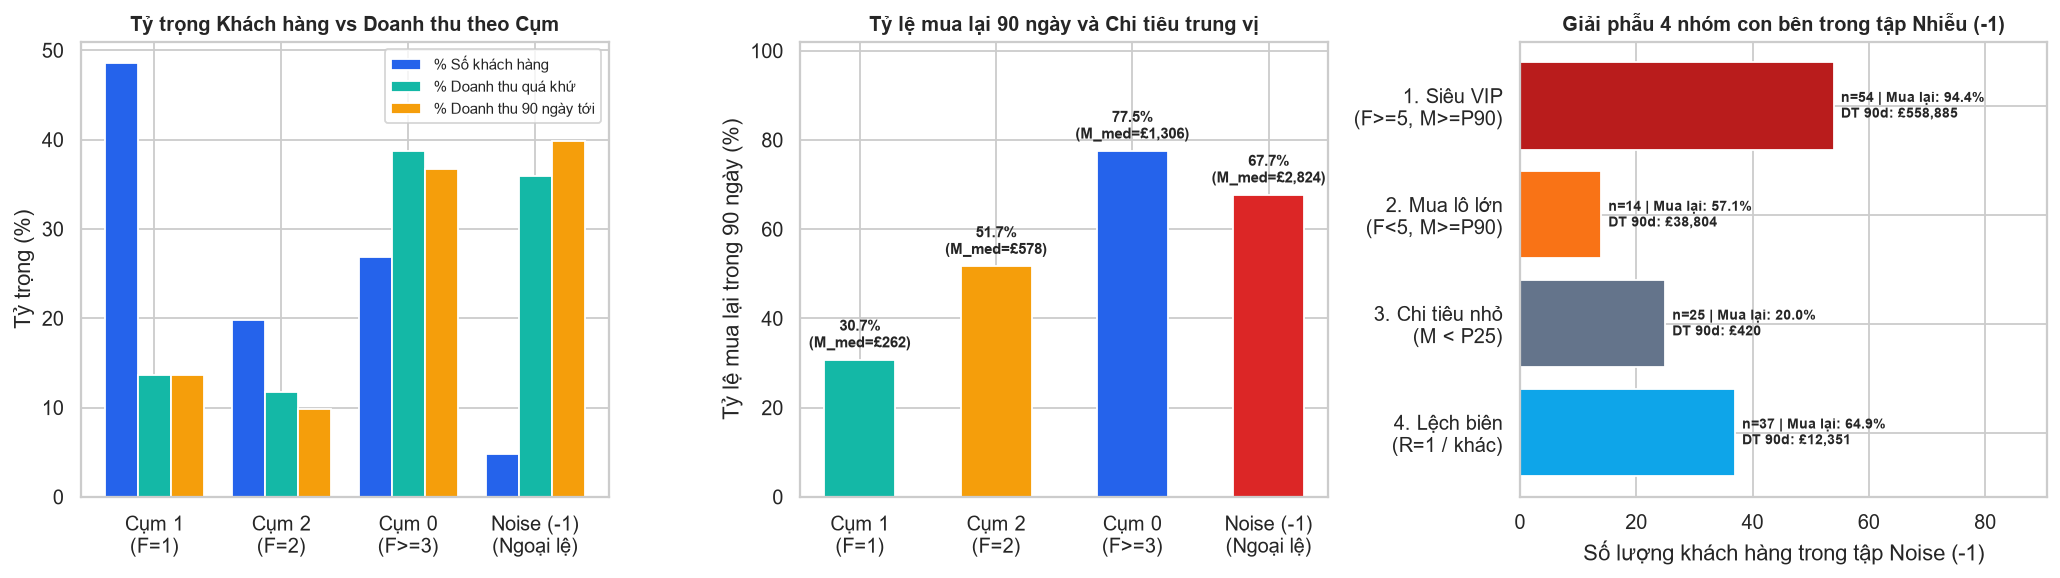

In [6]:
from dbscan import analyze_clusters_and_noise

dev_full_df, dev_cluster_prof, dev_noise_prof = analyze_clusters_and_noise(
    dev_rfm, dev_feat, dev_outcomes, dev_labels
)

print("=== BẢNG HỒ SƠ CHI TIẾT CÁC CỤM VÀ NHÓM NHIỄU TRÊN DEVELOPMENT ===")
print(dev_cluster_prof.to_string(index=False))

print("\n=== GIẢI PHẪU 4 NHÓM CON BÊN TRONG TẬP KHÁCH HÀNG NHIỄU (NOISE = -1, n = 130) ===")
print(dev_noise_prof.to_string(index=False))

# Hiển thị top 5 khách hàng chi tiêu cao nhất và thấp nhất trong nhóm Noise (-1)
noise_only = dev_full_df[dev_full_df["cluster"] == -1].sort_values("Monetary", ascending=False)
print("\n--- Top 5 Khách hàng Siêu VIP bị gán nhãn Noise (-1) ---")
print(noise_only[["CustomerID", "PrimaryCountry", "Recency", "Frequency", "Monetary", "repurchased_in_90d", "future_revenue"]].head(5).to_string(index=False))
print("\n--- Top 5 Khách hàng Chi tiêu Siêu nhỏ bị gán nhãn Noise (-1) ---")
print(noise_only[["CustomerID", "PrimaryCountry", "Recency", "Frequency", "Monetary", "repurchased_in_90d", "future_revenue"]].tail(5).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
order_c = [1, 2, 0, -1]
labels_x = ["Cụm 1\n(F=1)", "Cụm 2\n(F=2)", "Cụm 0\n(F>=3)", "Noise (-1)\n(Ngoại lệ)"]
prof_idx = dev_cluster_prof.set_index("cluster").loc[order_c]

x_pos = np.arange(len(order_c))
w = 0.26
axes[0].bar(x_pos - w, prof_idx["customer_share"] * 100, width=w, color=PALETTE[0], label="% Số khách hàng")
axes[0].bar(x_pos, prof_idx["past_monetary_share"] * 100, width=w, color=PALETTE[1], label="% Doanh thu quá khứ")
axes[0].bar(x_pos + w, prof_idx["future_revenue_share"] * 100, width=w, color=PALETTE[2], label="% Doanh thu 90 ngày tới")
axes[0].set_xticks(x_pos, labels_x)
axes[0].set_ylabel("Tỷ trọng (%)")
axes[0].set_title("Tỷ trọng Khách hàng vs Doanh thu theo Cụm", fontsize=11, fontweight="bold")
axes[0].legend(fontsize=8.5, frameon=True)

bars_rep = axes[1].bar(
    labels_x,
    prof_idx["repurchase_rate_90d"] * 100,
    color=[PALETTE[1], PALETTE[2], PALETTE[0], NOISE_COLOR],
    width=0.52,
)
for bar, (_, row) in zip(bars_rep, prof_idx.iterrows()):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.8,
        f"{row['repurchase_rate_90d']*100:.1f}%\n(M_med=£{row['monetary_median']:,.0f})",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
    )
axes[1].set_ylim(0, 102)
axes[1].set_ylabel("Tỷ lệ mua lại trong 90 ngày (%)")
axes[1].set_title("Tỷ lệ mua lại 90 ngày và Chi tiêu trung vị", fontsize=11, fontweight="bold")

short_noise = [
    "1. Siêu VIP\n(F>=5, M>=P90)",
    "2. Mua lô lớn\n(F<5, M>=P90)",
    "3. Chi tiêu nhỏ\n(M < P25)",
    "4. Lệch biên\n(R=1 / khác)",
]
axes[2].barh(short_noise, dev_noise_prof["customers"], color=["#b91c1c", "#f97316", "#64748b", "#0ea5e9"])
for idx, row in dev_noise_prof.iterrows():
    axes[2].text(
        row["customers"] + 1.2,
        idx,
        f"n={int(row['customers'])} | Mua lại: {row['repurchase_rate_90d']*100:.1f}%\nDT 90d: £{row['future_revenue_total']:,.0f}",
        va="center",
        fontsize=8,
        fontweight="bold",
    )
axes[2].set_xlim(0, max(dev_noise_prof["customers"]) * 1.68)
axes[2].invert_yaxis()
axes[2].set_xlabel("Số lượng khách hàng trong tập Noise (-1)")
axes[2].set_title("Giải phẫu 4 nhóm con bên trong tập Nhiễu (-1)", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

### Phân tích Chuyên sâu Các Cụm và Bản chất của Khách hàng Nhiễu (`Noise = -1`)
1. **Ba cụm khách hàng đại trà tạo thành bậc thang giá trị rõ rệt:**
   - **Cụm 1 — Khách mua 1 lần / Ngủ đông ($F = 1$, $n = 1,318$, chiếm $48.53\%$):** Có `Recency` trung vị cao nhất ($85.0$ ngày), `Monetary` trung vị thấp nhất (£262.10), và chỉ có **30.73%** quay lại mua trong 90 ngày tiếp theo.
   - **Cụm 2 — Khách lặp lại bước đầu ($F = 2$, $n = 538$, chiếm $19.81\%$):** Có `Recency` trung vị giảm xuống $44.0$ ngày, `Monetary` trung vị đạt £577.75 (gấp 2.2 lần Cụm 1), và tỷ lệ mua lại tăng vọt lên **51.67%**.
   - **Cụm 0 — Khách hàng trung thành cốt lõi ($F \in [3, 21]$, $n = 730$, chiếm $26.88\%$):** Có `Recency` trung vị $21.0$ ngày, `Frequency` trung vị $4.0$ hóa đơn, `Monetary` trung vị £1,305.84, đóng góp **38.76% tổng doanh thu quá khứ** và có tỷ lệ mua lại 90 ngày đạt **77.53%**.
2. **Giải phẫu nhóm Nhiễu (`Noise, cluster = -1`, $n = 130$, chiếm $4.79\%$):**
   - Trong DBSCAN, một khách hàng bị gán nhãn `-1` khi có ít hơn 8 láng giềng trong bán kính `eps = 0.45`. Do phân phối RFM có đuôi dài, tập `-1` thực chất là hợp của **4 nhóm ngoại lệ hoàn toàn khác biệt**:
     - **Nhóm 1 — Siêu VIP / Khách sỉ Cá voi ($F \ge 5$ & $\text{Monetary} \ge P_{90}$, $n = 54$ khách = $1.99\%$ toàn tập):** Có `Monetary` trung vị **£10,249.93** (trung bình **£17,411.07**, dẫn đầu là `CustomerID 14646` tại Hà Lan với £110,155.12 và `18102` tại Anh với £64,642.11). Chỉ riêng 54 khách hàng này chiếm tới **28.78% tổng doanh thu quá khứ (£940,197.58)**, đạt tỷ lệ mua lại **94.44%** và tạo ra **36.52% tổng doanh thu tương lai (£558,885.07)**!
     - **Nhóm 2 — Khách mua Lô lớn Ít lần ($F < 5$ & $\text{Monetary} \ge P_{90}$, $n = 14$ khách):** Điển hình là `CustomerID 12346` (1 đơn hàng £77,183.60 từ 134 ngày trước và không quay lại). Nhóm này có chi tiêu trung vị £6,515.57 nhưng tỷ lệ mua lại chỉ đạt **57.14%**.
     - **Nhóm 3 — Khách chi tiêu Siêu nhỏ ($	ext{Monetary} < P_{25}$, $n = 25$ khách):** Chi tiêu trung vị chỉ **£93.35** (thấp nhất là `16446` với £2.90 và `16738` với £3.75), tỷ lệ mua lại chỉ **20.00%**, đóng góp vỏn vẹn **0.03%** doanh thu tương lai.
     - **Nhóm 4 — Tổ hợp RFM Lệch biên ($n = 37$ khách):** Khách vừa mua sát ngày chốt (`Recency` trung vị $1.0$ ngày, $F = 3$, $M = \text{£789.79}$) nằm ở rìa mặt phẳng, có tỷ lệ mua lại **64.86%**.

---
## 4. Đánh giá Khả năng Phát hiện Cụm có Hình dạng Khác nhau

=== PHÂN TÍCH HÌNH HỌC ĐA CHIỀU (TRỊ RIÊNG HIỆP PHƯƠNG SAI) CỦA CÁC CỤM RFM ===
 cluster  customers  eigval_1  eigval_2  eigval_3  elongation_index  planarity_index  sphericity_index                                           shape_characterization
      -1        130    5.7822    1.9463  1.131792            0.4198           0.2374            0.4424              Phân tán bao quanh rìa không gian 3D (Outlier Halo)
       0        730    0.8980    0.4098  0.155259            0.3245           0.3845            0.4158 Ống / Đám mây thuôn dài 3D theo trục F-M (Elongated 3D Manifold)
       1       1318    0.6175    0.4118  0.000000            0.1834           1.0000            0.0000      Tấm phẳng / Dải băng 2D suy biến chiều F (2D Planar Ribbon)
       2        538    0.6839    0.3213  0.000000            0.3146           1.0000            0.0000      Tấm phẳng / Dải băng 2D suy biến chiều F (2D Planar Ribbon)

Chỉ số tương đồng Adjusted Rand Index (ARI) giữa DBSCAN và K-Means (k=3) trên R

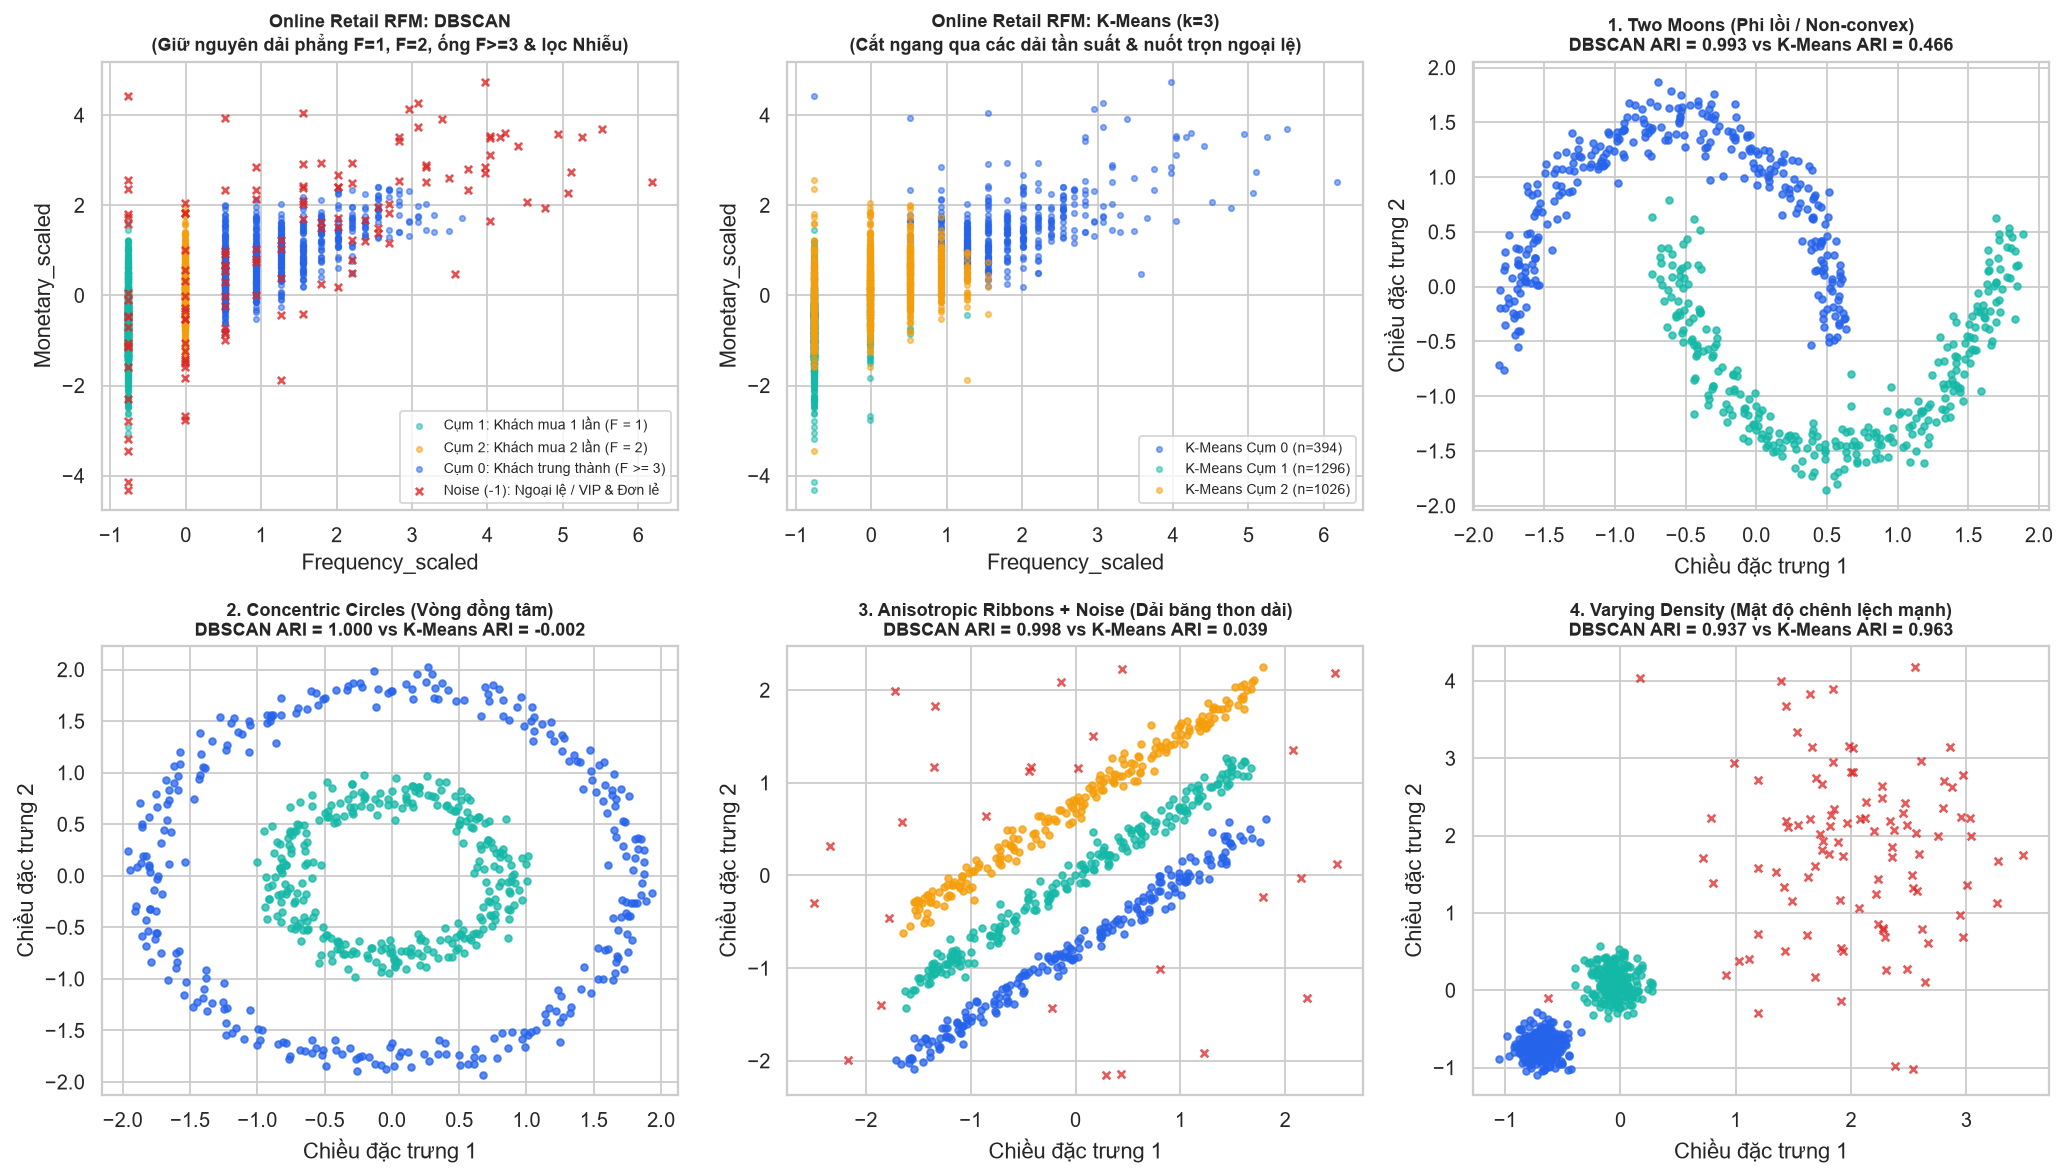

In [7]:
from dbscan import evaluate_cluster_geometry_and_shapes

rfm_geom_df, bench_df, shape_extra = evaluate_cluster_geometry_and_shapes(X_dev, dev_labels)

print("=== PHÂN TÍCH HÌNH HỌC ĐA CHIỀU (TRỊ RIÊNG HIỆP PHƯƠNG SAI) CỦA CÁC CỤM RFM ===")
print(rfm_geom_df.to_string(index=False))

print(f"\nChỉ số tương đồng Adjusted Rand Index (ARI) giữa DBSCAN và K-Means (k=3) trên RFM (không tính nhiễu): {shape_extra['ari_rfm_vs_kmeans']:.4f}")

print("\n=== THỰC NGHIỆM ĐỐI CHỨNG KHẢ NĂNG PHÁT HIỆN HÌNH DẠNG CỤM: DBSCAN VS K-MEANS ===")
print(bench_df.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
km_rfm = shape_extra["km_rfm_labels"]

for cid in [1, 2, 0, -1]:
    sub = dev_labels == cid
    axes[0, 0].scatter(
        dev_feat.loc[sub, "Frequency_scaled"],
        dev_feat.loc[sub, "Monetary_scaled"],
        s=16 if cid == -1 else 9,
        alpha=0.8 if cid == -1 else 0.5,
        color=cluster_palette[cid],
        marker="x" if cid == -1 else "o",
        label=cluster_titles[cid],
    )
axes[0, 0].set_title("Online Retail RFM: DBSCAN\n(Giữ nguyên dải phẳng F=1, F=2, ống F>=3 & lọc Nhiễu)", fontsize=10, fontweight="bold")
axes[0, 0].set_xlabel("Frequency_scaled")
axes[0, 0].set_ylabel("Monetary_scaled")
axes[0, 0].legend(loc="lower right", fontsize=7.5, frameon=True)

for cid, col in zip([0, 1, 2], PALETTE[:3]):
    sub = km_rfm == cid
    axes[0, 1].scatter(
        dev_feat.loc[sub, "Frequency_scaled"],
        dev_feat.loc[sub, "Monetary_scaled"],
        s=9,
        alpha=0.5,
        color=col,
        label=f"K-Means Cụm {cid} (n={int(sub.sum())})",
    )
axes[0, 1].set_title("Online Retail RFM: K-Means (k=3)\n(Cắt ngang qua các dải tần suất & nuốt trọn ngoại lệ)", fontsize=10, fontweight="bold")
axes[0, 1].set_xlabel("Frequency_scaled")
axes[0, 1].set_ylabel("Monetary_scaled")
axes[0, 1].legend(loc="lower right", fontsize=8, frameon=True)

target_axes = [axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]]
for ax, (b_name, (X_b, y_true, y_db, y_km)) in zip(target_axes, shape_extra["bench_plot_data"].items()):
    valid_t = y_true != -1
    y_db_eval = y_db[valid_t].copy()
    noise_pos = np.flatnonzero(y_db_eval == -1)
    if len(noise_pos) > 0:
        y_db_eval[noise_pos] = -np.arange(1, len(noise_pos) + 1)
    ari_db = adjusted_rand_score(y_true[valid_t], y_db_eval)
    ari_km = adjusted_rand_score(y_true[valid_t], y_km[valid_t])
    for cid in sorted(np.unique(y_db)):
        mask = y_db == cid
        col = NOISE_COLOR if cid == -1 else PALETTE[int(cid) % len(PALETTE)]
        ax.scatter(
            X_b[mask, 0],
            X_b[mask, 1],
            s=18 if cid == -1 else 14,
            alpha=0.75,
            color=col,
            marker="x" if cid == -1 else "o",
        )
    ax.set_title(f"{b_name}\nDBSCAN ARI = {ari_db:.3f} vs K-Means ARI = {ari_km:.3f}", fontsize=9.8, fontweight="bold")
    ax.set_xlabel("Chiều đặc trưng 1")
    ax.set_ylabel("Chiều đặc trưng 2")

fig.tight_layout()
plt.show()

### Đánh giá Khả năng Phát hiện Cụm có Hình dạng Khác nhau
1. **Trên không gian RFM thực tế của Online Retail:**
   - Phân tích trị riêng ($\lambda_1 \ge \lambda_2 \ge \lambda_3$) của ma trận hiệp phương sai từng cụm chứng minh các cụm RFM **không hề có dạng hình cầu đẳng hướng** ($	ext{Sphericity} = \sqrt{\lambda_3/\lambda_1} \ll 1$):
     - **Cụm 1 ($F=1$) và Cụm 2 ($F=2$)** có trị riêng thứ ba $\lambda_3 = 0.000000$, chỉ số độ phẳng **$\text{Planarity} = 1.0000$** và độ cầu **$\text{Sphericity} = 0.0000$**. Đây là hai **dải băng phẳng 2 chiều (2D Planar Ribbons)** dựng đứng song song trong không gian 3D.
     - **Cụm 0 ($F \ge 3$)** có $\lambda_1 = 0.8980, \lambda_2 = 0.4098, \lambda_3 = 0.1553$ ($\text{Elongation} = 0.3245, \text{Sphericity} = 0.4158$), tạo thành một **đám mây hình ống thuôn dài nghiêng theo đường chéo `Frequency–Monetary`**.
   - Trong khi **DBSCAN** bám theo liên thông mật độ để tách trọn vẹn từng dải phẳng $F=1, F=2$ và ống nghiêng $F \ge 3$ (đồng thời bóc tách lớp vỏ ngoại lệ `Noise = -1` có phương sai cực lớn $\lambda_1 = 5.7822$), thuật toán **K-Means ($k=3$)** lại áp đặt các mặt phân cách cầu Voronoi dẫn đến việc **cắt ngang qua các dải tần suất** (chỉ số tương đồng giữa hai thuật toán chỉ đạt $\text{ARI} = 0.4368$) và gộp toàn bộ khách hàng ngoại lệ vào các cụm thông thường.
2. **Trên bộ kiểm thử hình học chuẩn (Geometric Benchmarks):**
   - **Ưu thế tuyệt đối trên các cấu trúc phi lồi và thuôn dài:** DBSCAN đạt **$\text{ARI} = 0.9933$** trên *Two Moons* (K-Means: $0.4661$), **$\text{ARI} = 1.0000$** trên *Concentric Circles* (K-Means: $-0.0016$), và **$\text{ARI} = 0.9975$** trên *Anisotropic Ribbons + Noise* (K-Means cắt ngang dải băng nên chỉ đạt $\text{ARI} = 0.0387$, chênh lệch $+0.9588$).
   - **Giới hạn cốt lõi khi mật độ chênh lệch mạnh (*Varying Density*):** Ở kịch bản thứ 4 (hai cụm rất đặc nằm gần nhau và một cụm thứ ba rất thưa), với một ngưỡng `eps = 0.20` toàn cục để không làm dính hai cụm đặc, DBSCAN chỉ phát hiện được 2 cụm đặc và đánh trượt toàn bộ cụm thưa thứ ba thành `Noise (-1)` (làm $\text{ARI} = 0.9372, \text{NMI} = 0.7242$ thấp hơn mức $\text{ARI} = 0.9635, \text{NMI} = 0.9395$ của K-Means). Đây chính là nguyên nhân lý thuyết giải thích vì sao 54 khách hàng Siêu VIP (vùng mật độ thưa trên đuôi phân phối RFM) bị đẩy vào nhóm `Noise (-1)`.

---
## 5. Kiểm định Out-of-Time trên Tập `Final` và Đánh giá Chính sách Kinh doanh 15%

In [8]:
from dbscan import export_team_outputs

outputs_root = ROOT / "models" / "outputs"
phase_results = export_team_outputs(data_dir, outputs_root, best_eps, best_ms)

X_fin = fin_feat[["Recency_scaled", "Frequency_scaled", "Monetary_scaled"]].to_numpy(dtype=float)
fin_labels = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_fin)
_, fin_cluster_prof, fin_noise_prof = analyze_clusters_and_noise(fin_rfm, fin_feat, fin_outcomes, fin_labels)

print("=== BẢNG HỒ SƠ CÁC CỤM TRÊN TẬP FINAL (N = 3,314, eps = 0.45, min_samples = 8) ===")
print(fin_cluster_prof.to_string(index=False))

print("\n=== GIẢI PHẪU TẬP NHIỄU (NOISE = -1, n = 126) TRÊN TẬP FINAL ===")
print(fin_noise_prof.to_string(index=False))

# So sánh với các quy tắc Baseline đơn giản (Top Monetary & RFM Score) ở cùng hạn mức chọn 15% khách hàng
policy_rows = []
for phase_name, (rfm_p, out_p) in [("development", (dev_rfm, dev_outcomes)), ("final", (fin_rfm, fin_outcomes))]:
    base_df = evaluate_simple_rules(rfm_p, out_p)
    for _, r in base_df.iterrows():
        policy_rows.append({
            "Phase": phase_name,
            "Chính sách chọn 15% khách": r["rule"],
            "Số khách được chọn": int(r["selected_customers"]),
            "Tỷ lệ mua lại 90d (%)": round(float(r["selected_repurchase_rate"]) * 100, 2),
            "Doanh thu 90d (£)": round(float(r["selected_future_revenue"]), 2),
            "Tỷ trọng DT 90d (%)": round(float(r["future_revenue_share"]) * 100, 2),
        })
    for p_key, label_rule in [
        ("policy_default", "dbscan_cluster_priority (Mặc định: xếp Noise cuối)"),
        ("policy_vip_aware", "dbscan_vip_aware_priority (Tách VIP-Noise quá khứ)"),
    ]:
        p_info = phase_results[phase_name][p_key]
        policy_rows.append({
            "Phase": phase_name,
            "Chính sách chọn 15% khách": label_rule,
            "Số khách được chọn": int(p_info["selected_customers"]),
            "Tỷ lệ mua lại 90d (%)": round(float(p_info["selected_repurchase_rate"]) * 100, 2),
            "Doanh thu 90d (£)": round(float(p_info["selected_future_revenue"]), 2),
            "Tỷ trọng DT 90d (%)": round(float(p_info["future_revenue_share"]) * 100, 2),
        })

policy_comp_df = pd.DataFrame(policy_rows)
print("\n=== ĐỐI SÁNH CHÍNH SÁCH ƯU TIÊN 15% KHÁCH HÀNG TRÊN DEVELOPMENT & FINAL ===")
print(policy_comp_df.to_string(index=False))

=== BẢNG HỒ SƠ CÁC CỤM TRÊN TẬP FINAL (N = 3,314, eps = 0.45, min_samples = 8) ===
 cluster                                       cluster_label  customers  customer_share  recency_median  recency_iqr  frequency_median  frequency_min  frequency_max  monetary_median  monetary_mean  monetary_total  past_monetary_share  repurchase_rate_90d  future_revenue_mean  future_revenue_total  future_revenue_share
      -1 Noise (-1): Ngoại lệ (Siêu VIP & Đơn lẻ bất thường)        126          0.0380             8.0        26.00               5.0              1            126          4194.84       14559.19      1834458.29               0.3564               0.7222              7226.30             910513.71                0.3650
       0      Cụm 0: Khách hàng Trung thành Cốt lõi (F >= 3)       1183          0.3570            35.0        55.00               4.0              3             27          1447.54        2025.88      2396621.42               0.4656               0.7844               910.49  

### Phân tích Kết quả Kiểm định Out-of-Time trên Tập `Final` và Chính sách Chọn 15% Khách hàng
- **Tính nhất quán cấu trúc trên tập `Final` ($N = 3,314$):** Khi áp dụng nguyên vẹn bộ tham số đã chốt từ `Development` (`eps = 0.45, min_samples = 8`) sang tập `Final` mà không tinh chỉnh lại:
  - Mô hình tái lập chính xác cấu trúc phân tầng hành vi: **Cụm 1 ($F=1$, $n=1,352$)** có tỷ lệ mua lại **36.91%**, **Cụm 2 ($F=2$, $n=640$)** đạt **51.56%**, **Cụm 0 ($F \in [3, 27]$, $n=1,183$)** đạt **78.44%**, và phát hiện thêm **Cụm 3 ($n=13$)** gồm các khách hàng mua rất gần (`Recency = 1` ngày, $F \in [5, 9]$) có tỷ lệ mua lại lên tới **84.62%**.
  - Nhóm **Noise (`-1`, $n=126$, chiếm $3.80\%$)** tiếp tục chứa **58 khách hàng Siêu VIP** (tỷ lệ mua lại **94.83%**, tạo ra **£878,940.19 = 35.23% tổng doanh thu tương lai** của toàn bộ 3,314 khách hàng).
- **Giải thích sự khác biệt lớn trong bài toán chọn 15% khách hàng ưu tiên:**
  - Quy tắc mặc định `dbscan_cluster_priority` (được định nghĩa trong `temporal_evaluation.py`) mặc định đẩy toàn bộ nhãn `-1` xuống cuối danh sách ưu tiên, vô tình loại bỏ nhóm Siêu VIP nằm trong `-1`. Hệ quả là dù tỷ lệ mua lại đạt rất cao (**87.22%** trên `Development` và **89.94%** trên `Final`), tỷ trọng doanh thu 90 ngày bao phủ chỉ đạt **30.05%** và **30.67%**.
  - Khi áp dụng quy tắc **`dbscan_vip_aware_priority`** (chỉ dùng dữ liệu quá khứ: tách các điểm `-1` có $F \ge 5$ và $\text{Monetary} \ge P_{90}$ thành phân khúc **VIP-Noise** ưu tiên số 1 trước Cụm 0), tỷ lệ mua lại tăng lên **87.96%** (`Development`) và **90.54%** (`Final` — vượt qua cả `top_monetary` 85.71% và `rfm_score` 90.34%), đồng thời tỷ trọng doanh thu 90 ngày tăng gấp đôi lên **64.58%** (`Development`) và **62.13%** (`Final`), tiệm cận chuẩn cơ sở `rfm_score` (64.11% và 62.66%)!

### Q&A
- **Làm thế nào để tối ưu hóa hai tham số `eps` và `min_samples` của DBSCAN trên dữ liệu RFM Online Retail?**
  Kết hợp quy tắc lý thuyết $\text{min\_samples} \approx \ln(N) = \ln(2716) \approx 8$ (thỏa mãn $\ge 2D = 6$), phân tích điểm gãy Kneedle trên đồ thị khoảng cách láng giềng thứ 8 (`eps = 0.457` tại phân vị 91.16%) và tìm kiếm lưới (Grid Search) trên 88 cấu hình giúp xác định bộ tham số tối ưu là **`eps = 0.45, min_samples = 8`**. Ngưỡng `eps = 0.45` nằm chính xác trong khoảng trống cấu trúc giữa các mặt phẳng tần suất rời rạc ($\Delta F_{\text{scaled}}(3 \to 4) = 0.4119 < 0.45 < \Delta F_{\text{scaled}}(2 \to 3) = 0.5310$), giúp mô hình tách sạch 3 phân khúc hành vi mà không sinh ra cụm vụn.
- **Các cụm tìm được và những khách hàng bị DBSCAN xem là nhiễu (`Noise = -1`) mang đặc điểm gì?**
  Ba cụm chính phân tách khách hàng theo bậc thang gắn kết rõ rệt: Cụm 1 (Mua 1 lần, $48.53\%$ khách, tỷ lệ mua lại 90 ngày đạt $30.73\%$), Cụm 2 (Mua 2 lần, $19.81\%$ khách, mua lại $51.67\%$) và Cụm 0 (Khách trung thành $F \ge 3$, $26.88\%$ khách, mua lại $77.53\%$). Nhóm khách hàng bị xem là nhiễu (`cluster = -1`, chiếm $4.79\%$ trên `Development` và $3.80\%$ trên `Final`) không phải là dữ liệu lỗi mà là các điểm nằm ở vùng mật độ thưa ở hai đầu cực trị: gồm nhóm **Siêu VIP / Cá voi** ($54$ khách trên `Development`, chi tiêu trung vị £10,249.93, tỷ lệ mua lại $94.44\%$ và đóng góp tới $36.52\%$ tổng doanh thu tương lai toàn tập) và nhóm **Khách mua đơn lẻ siêu nhỏ / lệch biên** ($25$ khách có chi tiêu $< P_{25}$ với trung vị £93.35 và tỷ lệ mua lại chỉ $20.00\%$).
- **Khả năng phát hiện cụm có hình dạng khác nhau của DBSCAN được thể hiện và giới hạn như thế nào?**
  Phân tích hiệp phương sai 3 chiều chứng minh DBSCAN phát hiện chính xác hai cụm có dạng **dải băng phẳng 2D suy biến** ($\lambda_3 = 0, \text{Planarity} = 1.0000$ tại $F=1$ và $F=2$) và một cụm **hình ống thuôn dài 3D** ($	ext{Elongation} = 0.3245$ tại $F \ge 3$), trong khi K-Means cắt ngang qua các dải tần suất ($	ext{ARI}$ giữa hai mô hình chỉ đạt $0.4368$). Trên bộ dữ liệu kiểm thử hình học, DBSCAN vượt trội hoàn toàn trước K-Means trên các cụm phi lồi (*Two Moons*: $\text{ARI} = 0.9933$ so với $0.4661$), vòng đồng tâm (*Concentric Circles*: $\text{ARI} = 1.0000$ so với $-0.0016$) và dải băng thon dài có nhiễu (*Anisotropic Ribbons*: $\text{ARI} = 0.9975$ so với $0.0387$), nhưng bộc lộ giới hạn trên dữ liệu có mật độ chênh lệch quá lớn (*Varying Density*: chỉ tìm được 2/3 cụm và đánh trượt cụm thưa thành nhiễu với $\text{ARI} = 0.9372, \text{NMI} = 0.7242$ so với $\text{ARI} = 0.9635, \text{NMI} = 0.9395$ của K-Means).

### Data Analysis Key Findings
- **Hiệu năng nội tại và cấu trúc cụm ổn định qua thời gian:** Tại cấu hình tối ưu `eps = 0.45, min_samples = 8`, tập `Development` ($N = 2,716$) hình thành 3 cụm với Silhouette đạt **0.2243**, Davies-Bouldin đạt **1.4610**, Calinski-Harabasz đạt **1,422.83** và tỷ lệ nhiễu **4.79%** ($130$ khách). Khi áp dụng cố định sang tập `Final` ($N = 3,314$), tỷ lệ nhiễu giữ ở mức **3.80%** ($126$ khách) và bậc thang tỷ lệ mua lại 90 ngày tiếp tục duy trì thứ tự nghiêm ngặt: Cụm 1 đạt **36.91%**, Cụm 2 đạt **51.56%**, Cụm 0 đạt **78.44%** và Cụm 3 (nhóm mua sát ngày chốt `Recency = 1`) đạt **84.62%**.
- **Sự tập trung doanh thu cực lớn trong nhóm Nhiễu Siêu VIP:** Nhóm `Noise (-1)` chỉ chiếm **4.79%** số khách hàng trên `Development` (**3.80%** trên `Final`) nhưng nắm giữ tới **35.92%** tổng doanh thu quá khứ (**35.64%** trên `Final`) và **39.89%** tổng doanh thu 90 ngày tiếp theo (**36.50%** trên `Final`). Riêng phân nhóm Siêu VIP ($F \ge 5, \text{Monetary} \ge P_{90}$) bên trong tập nhiễu chỉ gồm **54 khách hàng** ($1.99\%$ tổng số khách) nhưng mang lại **£558,885.07** doanh thu tương lai trên `Development` và **58 khách hàng** mang lại **£878,940.19** trên `Final`.
- **Tác động quyết định của việc phân loại lại tập Nhiễu đối với chính sách chọn 15% khách hàng:** Nếu xếp toàn bộ nhãn `-1` xuống cuối như quy tắc mặc định `dbscan_cluster_priority`, việc chọn 15% khách hàng ($407$ khách trên `Development`, $497$ khách trên `Final`) chỉ bao phủ được **30.05%** và **30.67%** doanh thu tương lai. Ngược lại, khi tách nhóm VIP-Noise (dựa thuần túy trên ngưỡng $F \ge 5$ và $\text{Monetary} \ge P_{90}$ quá khứ) để ưu tiên trước Cụm 0, tỷ lệ mua lại 90 ngày đạt **87.96%** (`Development`) và **90.54%** (`Final`), đồng thời tỷ trọng doanh thu tương lai tăng vọt lên **64.58%** và **62.13%**.

### Insights or Next Steps
- **Triển khai cơ chế Hậu xử lý Hai Tầng (Two-Stage Noise Triage) cho DBSCAN trong sản xuất:** Không loại bỏ nhãn `-1` của DBSCAN một cách cơ học; cần tự động phân tách tập `-1` bằng quy tắc ngưỡng quá khứ ($F \ge 5$ và $\text{Monetary} \ge P_{90}$) để chuyển nhóm **Siêu VIP / Cá voi** sang kênh chăm sóc khách hàng trọng điểm (Key Account Management), đồng thời tách nhóm chi tiêu siêu nhỏ ($	ext{Monetary} < P_{25}$) ra khỏi các chiến dịch tiếp thị tốn kém chi phí.
- **Mở rộng thử nghiệm sang HDBSCAN hoặc OPTICS:** Vì dữ liệu RFM có độ chênh lệch mật độ rất lớn giữa đám mây khách hàng mua 1 lần ($48.5\%$ dữ liệu nằm trên một mặt phẳng duy nhất) và vùng đuôi khách hàng VIP thưa thớt, bước tiếp theo có thể đối sánh DBSCAN với thuật toán mật độ biến thiên (HDBSCAN/OPTICS) và kết hợp cùng kết quả của K-Means, Agglomerative, GMM trong bảng tổng hợp của cả nhóm.